# Testing the Classification Algorithm

## Preparations

This notebook is for testing the classification pipeline.

### Importing necessary libraries

In [ ]:
import time
import asyncio

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
)

In [ ]:
from backend.scripts.database_manager import DatabaseManager
from backend.scripts.classes import ClassManager

Connect to DB

In [ ]:
db = DatabaseManager()
await db.connect()

class_manager = ClassManager(db)

### Load dataset

Load crops with embeddings and class labels

In [ ]:
rows = await db.get_crops_with_embeddings_class(page=0, page_size=2000)
print(f"Found {len(rows)} crops")

Prepare lists for evaluation

In [ ]:
crop_paths = [r['crop_path'] for r in rows]
true_labels = [r['assigned_class'] for r in rows]

In [ ]:
df1 = pd.DataFrame({'crop_path': crop_paths, 'true_label': true_labels})
df1['true_label'] = df1['true_label'].astype(str)
df1

Classes ranked by instances

In [ ]:
counts_df = df1.groupby('true_label').size().reset_index(name='count').sort_values('count', ascending=False)
counts_df

All classes in the dataset:

In [ ]:
all_classes_1 = sorted(df1['true_label'].unique().tolist())

### Methods

In [ ]:
async def classify_all(df, limit_per_class=2, threshold=0.8, concurrency=1, class_names=None):
    """
    Classifies all crops in the dataframe through the leave-one-out cross-validation algorithm.

    :param df: The dataframe to classify
    :param limit_per_class: The maximum number of crops per class to compare against
    :param threshold: The threshold to compare against
    :param concurrency: The maximum number of concurrent operations
    :param class_names: The names of the classes to consider
    :return: The dataframe with the results of the classification
    """
    sem = asyncio.Semaphore(concurrency)
    results = []

    async def _worker(crop_path, true_label):
        async with sem:
            t0 = time.perf_counter()
            res = await class_manager.classify_crop(crop_path, limit_per_class=limit_per_class, threshold=threshold, class_names=class_names)
            t1 = time.perf_counter()
            return {
                'crop_path': crop_path,
                'true_label': true_label,
                'predicted_class': res['predicted_class'],
                'confidence': res['confidence'],
                'runtime': t1 - t0
            }

    for _, row in df.iterrows():
        results.append(await _worker(row['crop_path'], row['true_label']))

    return pd.DataFrame(results)

In [ ]:
def compute_classification_metrics(df_results, labels=None):
    """Compute evaluation metrics for the classification results.
    :param df_results: Classification results
    :param labels: The labels of the database
    :return: The evaluation metrics
    """
    y_true = df_results['true_label'].fillna(None).tolist()
    y_pred = df_results['predicted_class'].fillna(None).tolist()

    acc = accuracy_score(y_true, y_pred)
    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels,average='macro', zero_division=0)
    precision_micro, recall_micro, f1_micro, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average='micro', zero_division=0)
    report = classification_report(y_true, y_pred, labels=labels, zero_division=0, output_dict=True)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    if labels is None:
        labels = sorted(list(set(y_true) | set(y_pred)))

    return {
        'accuracy': acc,
        'precision_macro': precision_macro,
        'recall_macro': recall_macro,
        'f1_macro': f1_macro,
        'precision_micro': precision_micro,
        'recall_micro': recall_micro,
        'f1_micro': f1_micro,
        'class_report': report,
        'confusion_matrix': cm,
        'labels': labels
    }

In [ ]:
def sample_classes(all_classes, db_k, query_k, overlap_ratio, seed=None):
    """
    Samples the classes into subsets of randomized query and database classes
    :param all_classes:
    :param db_k:
    :param query_k:
    :param overlap_ratio:
    :param seed:
    :return: The classes to be included in the database and query
    """
    random.seed(seed)

    # choose overlap_count
    overlap_count = int(min(db_k, query_k) * overlap_ratio)
    overlap = set(random.sample(all_classes, k=overlap_count))

    remaining = list(set(all_classes) - overlap)
    db_extra = set(random.sample(remaining, k=db_k - overlap_count))
    remaining = list(set(remaining) - db_extra)
    query_extra = set(random.sample(remaining, k=query_k - overlap_count))

    db_classes = list(overlap | db_extra)
    query_classes = list(overlap | query_extra)

    return db_classes, query_classes

## Quantitative Evaluation

### Classification Metrics

#### Confusion Matrix

Because the confusion matrix can be very large, we will only use a subset of the data for computation. \
The inputs used for limits_per_class and similarity threshold are the ones that are used on the website and app.

In [14]:
db_classes_cm, query_classes_cm = sample_classes(all_classes_1, 20, 20, 1.0, 2)
df_subset = df1[df1['true_label'].isin(query_classes_cm)].reset_index(drop=True)

res_df_cm = await classify_all(df_subset, limit_per_class=2, threshold=0.8, class_names=db_classes_cm)
metrics_cm = compute_classification_metrics(res_df_cm, query_classes_cm)

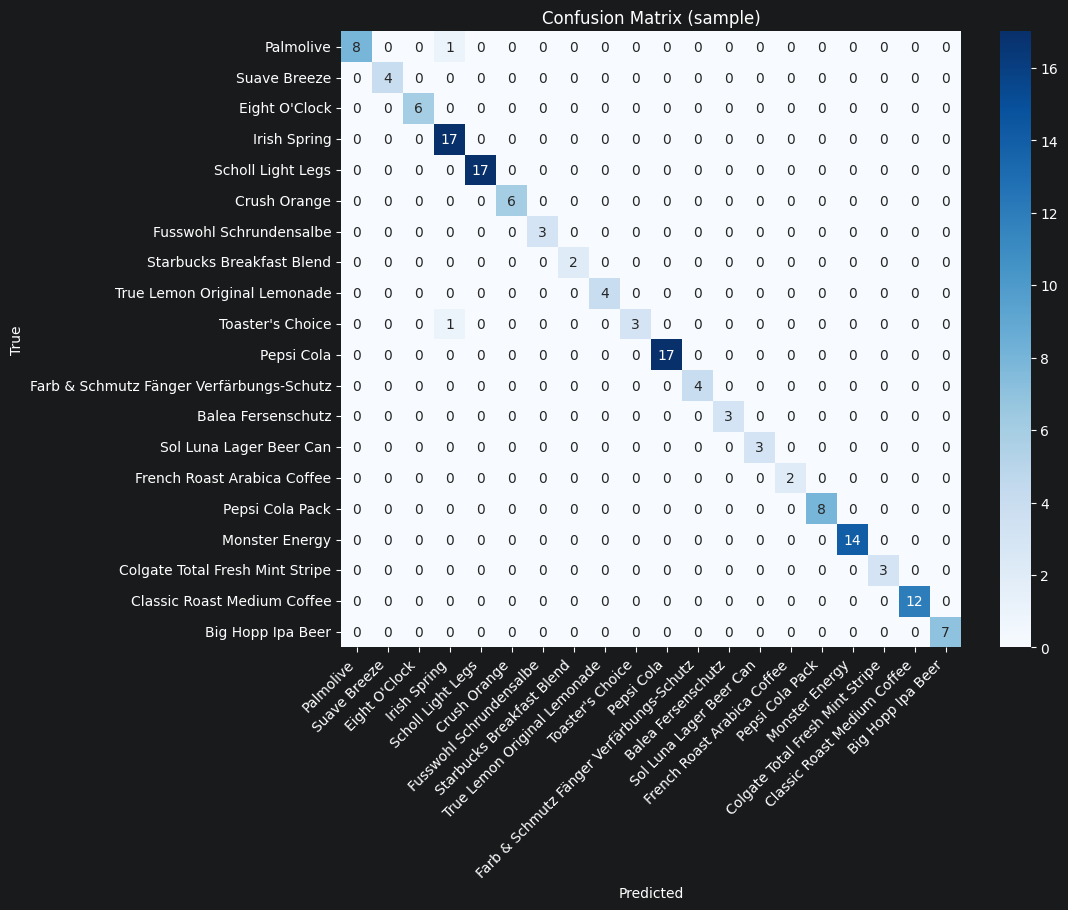

In [15]:
# Confusion Matrix plot
plt.figure(figsize=(10,8))
sns.heatmap(metrics_cm['confusion_matrix'], xticklabels=metrics_cm['labels'], yticklabels=metrics_cm['labels'], annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (sample)')
plt.xticks(rotation=45, ha='right')
plt.show()

For the following tests we need to classify all embeddings to compute the accuracy, recall, precision and F1-Score. \
The inputs used for limits_per_class and similarity threshold are the ones that are used on the website and app.

In [16]:
res_df = await classify_all(df1, limit_per_class=2, threshold=0.8)
metrics = compute_classification_metrics(res_df, all_classes_1)

#### Accuracy

Accuracy is the ratio of correctly classified samples to the total number of samples.

 The Formula is: \
$Accuracy= \frac{True Positives + True Negatives}{ True Positives + True Negatives + False Positives + False Negatives }$

It gives us an overall measure of how well the classification model is performing. \
However, it can be misleading in cases where the classes are imbalanced, as it may be high even if the model is only correctly classifying the majority class.

In [17]:
print(round(metrics['accuracy'], 4))

0.9526


#### Precision

Precision is the ratio of true positives to the total number of predicted positives.

The formula is: \
$Precision = \frac{True Positives}{True Positives + False Positives}$


It measures how many of the samples that were predicted as positive are actually positive. \
A high precision means that the model is making few false positive errors, while a low precision means that the model is making many false positive errors. \
In a multi-class classification setting, we can compute the precision for each class and then average them to get the macro-averaged precision, or we can compute the precision globally by counting the total true positives and false positives across all classes to get the micro-averaged precision.

##### Macro-Averaged Precision

Macro averaged precision is calculated by computing the precision for each class independently and then taking the average of these precisions.


The formula is: \
$Precision_{macro} = \frac{1}{N} \sum_{i=1}^{N} Precision_i$ \
Where $N$ is the number of classes and $Precision_i$ is the precision for class $i$.


This method treats all classes equally, regardless of their support (number of samples).
In cases where the classes are imbalanced, the macro-averaged precision can be heavily influenced by the performance on the minority classes, as it gives equal weight to all classes.


In [18]:
print(round(metrics['precision_macro'], 4))

0.8994


##### Micro-Averaged Precision

Micro averaged precision is calculated by counting the total true positives and false positives across all classes and then computing the precision from these totals.

The formula is: \
$Precision_{micro} = \frac{\sum_{i=1}^{N} TP_i}{\sum_{i=1}^{N} TP_i + \sum_{i=1}^{N} FN_i}$ \

This method gives more weight to the classes with more samples, as it aggregates the contributions of all classes to compute the average metric. \
In cases where the classes are imbalanced, the micro-averaged precision can be dominated by the performance on the majority class.

In [19]:
print(round(metrics['precision_micro'], 4))

0.957


#### Recall

Recall is a metric that calculates the ratio of true positives to the total amount of actually positives.

The Formula is: \
$Recall = \frac{True Positives}{True Positives + False Negatives} $

It measures how many of the positive samples were rightly predicted as positive.

##### Macro-Averaged Recall

The formula is: \
$Recall_{macro} = \frac{1}{N} \sum_{i=1}^{N} Recall_i$

In [20]:
print(round(metrics['recall_macro'], 4))

0.8813


##### Micro-Averaged Recall

The formula is: \
$Recall_{micro} = \frac{\sum_{i=1}^{N} TP_i}{\sum_{i=1}^{N} TP_i + \sum_{i=1}^{N} FN_i}$

In [21]:
print(round(metrics['recall_micro'], 4))

0.9526


**F1-Score**

The F1-Score is calculated by taking the harmonic mean of precision and recall.

The Formula is: \
$ F_{1} = \frac{2}{Recall^{-1} + Precision^{-1}} = 2 * \frac{Precision * Recall}{Precision + Recall } = \frac{2*TP}{2*TP + FP + FN }$

##### Macro-averaged F1-Score

The Formula is: \
$Macro F_1 = \frac{1}{N} \sum_{i=1}^{N} F_{1,i}$


In [22]:
print(round(metrics['f1_macro'], 4))

0.8831


##### Micro-averaged F1-Score

The formula is: \
$Micro F_1 = \frac{2*\sum_{i=1}^{N} TP_i}{2*\sum_{i=1}^{N} TP_i + \sum_{i=1}^{N} FP_i + \sum_{i=1}^{N} FN_i }$

In [23]:
print(round(metrics['f1_micro'], 4))

0.9548


### Class Performance

Classification Report

In [24]:
df_metrics = pd.DataFrame(metrics['class_report']).T
df_metrics = df_metrics.drop_duplicates(keep='first')
# df_metrics

## Scalability Evaluation

### Metrics at different Reference Class Set Sizes (K)

Evaluate metrics at different values of reference class set size (K)

In [26]:
ref_class_size = np.arange(1, 11, 1).tolist()
recall_micro = []
recall_macro = []
runtime = []

for k in ref_class_size:
    res_df_k = await classify_all(df1, limit_per_class=k, threshold=0.8)
    metrics_k = compute_classification_metrics(res_df_k, all_classes_1)
    recall_macro.append(metrics_k['recall_macro'])
    recall_micro.append(metrics_k['recall_micro'])
    runtime.append(res_df_k['runtime'])

#### Recall vs. Reference Class Set Size (K)

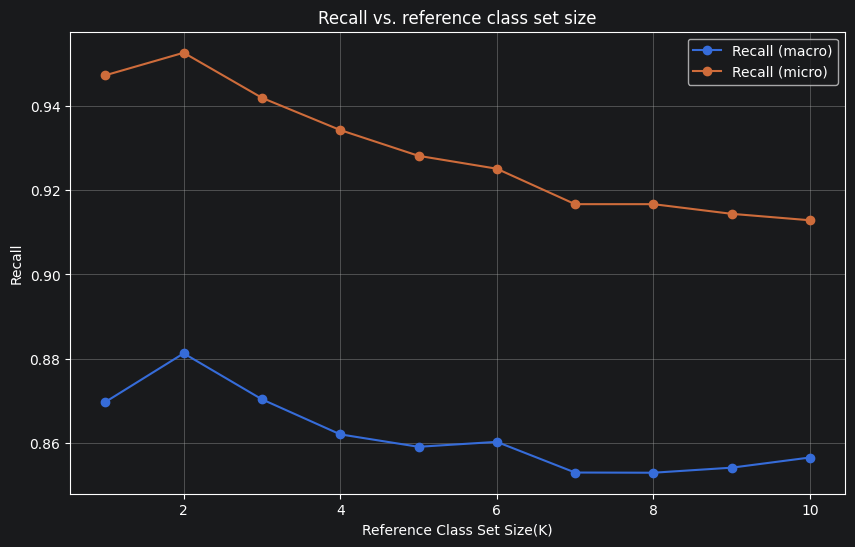

In [27]:
plt.figure(figsize=(10,6))
plt.plot(ref_class_size, recall_macro, marker='o', label='Recall (macro)')
plt.plot(ref_class_size, recall_micro, marker='o', label='Recall (micro)')
plt.xlabel('Reference Class Set Size(K)')
plt.ylabel('Recall')
plt.title('Recall vs. reference class set size')
plt.legend()
plt.grid(True)
plt.show()

In the graph it becomes evident that there is no clear correlation between more reference embeddings compared and better recall scores.
The intuitive result would be that more reference embeddings are a better representation of the class and lead to better accuracy, which makes this result to be investigated further and to come up with an explanation.

It is to be evaluated what would happen if a better selection the reference embeddings would influence the results positively. There might be a problem where the first instances returned in the query to be compared against are not the representation of the class, i.e. if they are an edge case and not the most typical depiction of the product.

A different approach is to make an average of all class embeddings, which also would lie in the area the class embeddings and would itself be identified as part of the class.

#### Runtime vs. Reference Class Set Size (K)

In [28]:
runtime_averages = [np.mean(r) for r in runtime]

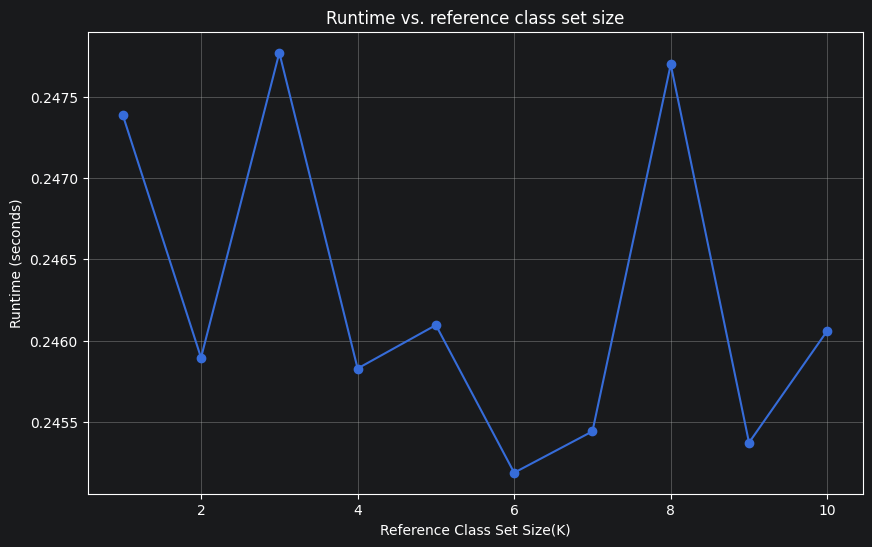

In [29]:
plt.figure(figsize=(10,6))
plt.plot(ref_class_size, runtime_averages, marker='o')
plt.xlabel('Reference Class Set Size(K)')
plt.ylabel('Runtime (seconds)')
plt.title('Runtime vs. reference class set size')
plt.grid(True)
plt.show()

### Accuracy & Runtime vs. Number of Classes

To determine how well the algorithm works with different amounts of classes to compare against, we can look at the accuracy and runtime at different number of classes.

The inputs used for limits_per_class and similarity threshold are the ones that are used on the website and app.

In [30]:
num_classes_array = [min(n, len(all_classes_1)) for n in [1,2,5,10,20,50,100,200]]
accuracies_nc = []
runtimes_nc = []

for num_classes in num_classes_array:
    db_classes_nc, query_classes_nc = sample_classes(all_classes_1, num_classes, num_classes, 1.0, 1)
    df_subset_nc = df1[df1['true_label'].isin(query_classes_nc)].reset_index(drop=True)

    res_df_nc = await classify_all(df_subset_nc, limit_per_class=10, threshold=0.8, class_names=db_classes_nc)
    metrics_nc = compute_classification_metrics(res_df_nc, query_classes_nc)
    accuracies_nc.append(metrics_nc['accuracy'])
    runtimes_nc.append(res_df_nc['runtime'])

C:\Users\2dani\PycharmProject\ImageEmbeddings\backend\.venv\Lib\site-packages\sklearn\metrics\_classification.py:614: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


#### Accuracy vs. Number of Classes

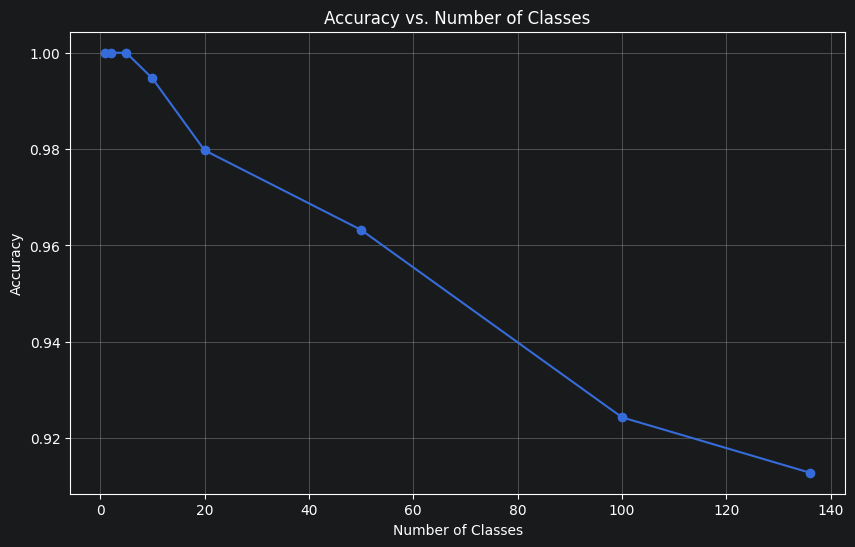

In [31]:
plt.figure(figsize=(10,6))
plt.plot(num_classes_array, accuracies_nc, marker='o')
plt.xlabel('Number of Classes')
plt.ylabel('Accuracy')
plt.title('Accuracy vs. Number of Classes')
plt.grid(True)
plt.show()

#### Runtime vs. Number of Classes

In [32]:
runtime_nc_averages = [np.mean(r) for r in runtimes_nc]

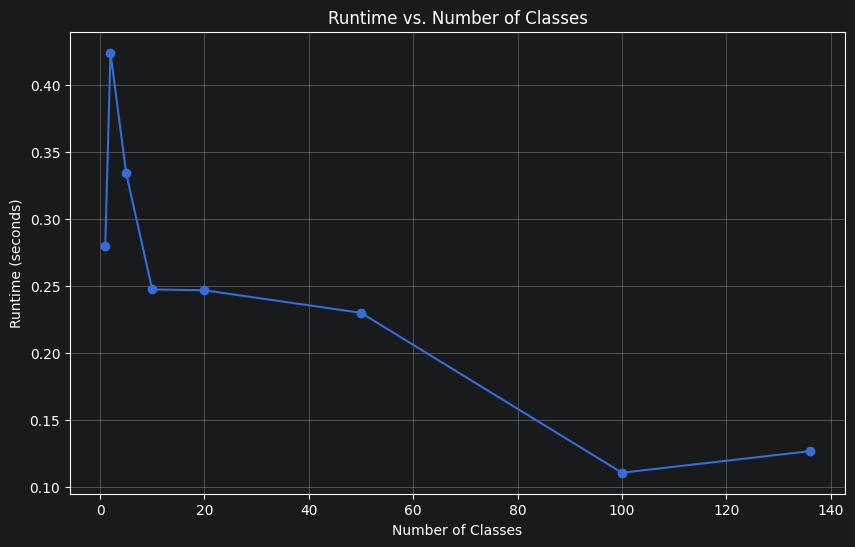

In [33]:
plt.figure(figsize=(10, 6))
plt.plot(num_classes_array, runtime_nc_averages, marker='o')
plt.xlabel('Number of Classes')
plt.ylabel('Runtime (seconds)')
plt.title('Runtime vs. Number of Classes')
plt.grid(True)
plt.show()

### Metrics at different Similarity Thresholds

The Similarity Threshold determines how strict the classification is. We will evaluate the metrics at different threshold values to see how it affects the performance.
The threshold is a value between 0 and 1 that determines how similar a crop must be to the reference class examples to be classified as that class. A higher threshold means that the crop must be more similar to the reference examples to be classified as that class, which can lead to higher precision but lower recall. A lower threshold means that the crop can be less similar to the reference examples to be classified as that class, which can lead to higher recall but lower precision.

We compute the classification of all crops in the dataframe with an initial threshold of 0, to reduce compution.
The input used for limits_per_class is the one that is used on the website and app.

In [34]:
res_all = await classify_all(df1, limit_per_class=2, threshold=0)

We apply the thresholds manually, compute the metrics and save them for each iteration.

In [35]:
thresholds = np.arange(0.7, 0.95, 0.01).tolist()
accuracies_t = []
precisions_t_micro = []
recalls_t_micro = []
f1score_t_micro = []
precisions_t_macro = []
recalls_t_macro = []
f1score_t_macro = []

for threshold_t in thresholds:
    res_t = res_all.copy()
    res_t['predicted_at_t'] = res_t.apply(lambda r: r['predicted_class'] if r['confidence'] >= threshold_t else None, axis=1)
    df_eval_t = res_t.copy()
    df_eval_t['predicted_class'] = df_eval_t['predicted_at_t']
    metrics_t = compute_classification_metrics(df_eval_t, all_classes_1)

    accuracies_t.append(metrics_t['accuracy'])

    # Micro averaged
    precisions_t_micro.append(metrics_t['precision_micro'])
    recalls_t_micro.append(metrics_t['recall_micro'])
    f1score_t_micro.append(metrics_t['f1_micro'])

    # Macro Averaged
    precisions_t_macro.append(metrics_t['precision_macro'])
    recalls_t_macro.append(metrics_t['recall_macro'])
    f1score_t_macro.append(metrics_t['f1_macro'])


The optimal threshold can be determined by analyzing the precision-recall tradeoff.

#### Accuracy-Similarity Treshold


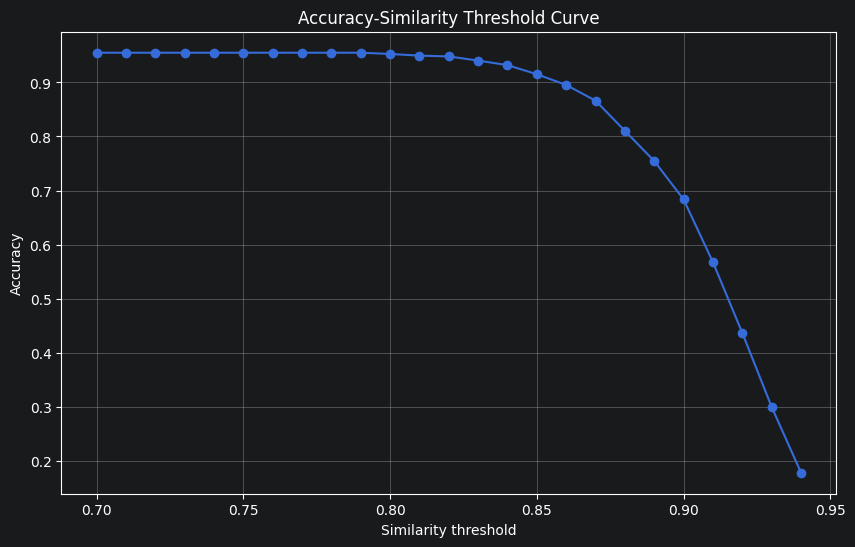

In [36]:
plt.figure(figsize=(10,6))
plt.plot(thresholds, accuracies_t, marker='o')
plt.xlabel('Similarity threshold')
plt.ylabel('Accuracy')
plt.title('Accuracy-Similarity Threshold Curve')
plt.grid(True)
plt.show()

#### Precision-Similarity Threshold

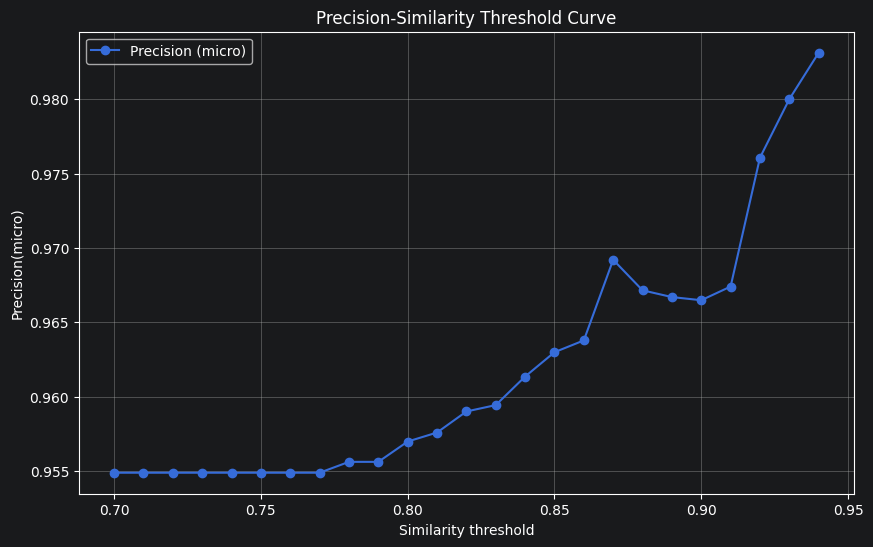

In [37]:
plt.figure(figsize=(10,6))
plt.plot(thresholds, precisions_t_micro, marker='o', label='Precision (micro)')
plt.xlabel('Similarity threshold')
plt.ylabel('Precision(micro)')
plt.title('Precision-Similarity Threshold Curve')
plt.legend()
plt.grid(True)
plt.show()

#### Recall-Similarity Threshold

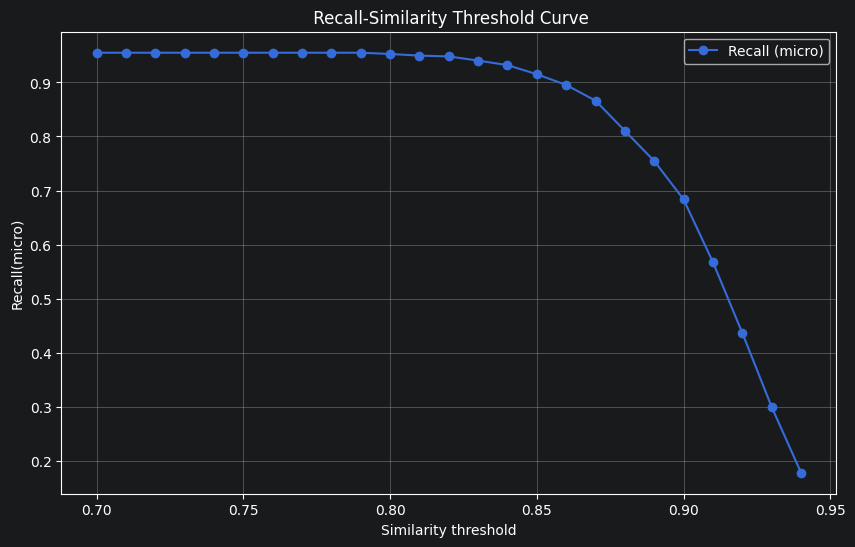

In [38]:
plt.figure(figsize=(10,6))
plt.plot(thresholds, recalls_t_micro, marker='o', label='Recall (micro)')
plt.xlabel('Similarity threshold')
plt.ylabel('Recall(micro)')
plt.title(' Recall-Similarity Threshold Curve')
plt.legend()
plt.grid(True)
plt.show()

#### F1-Score-Similarity Threshold

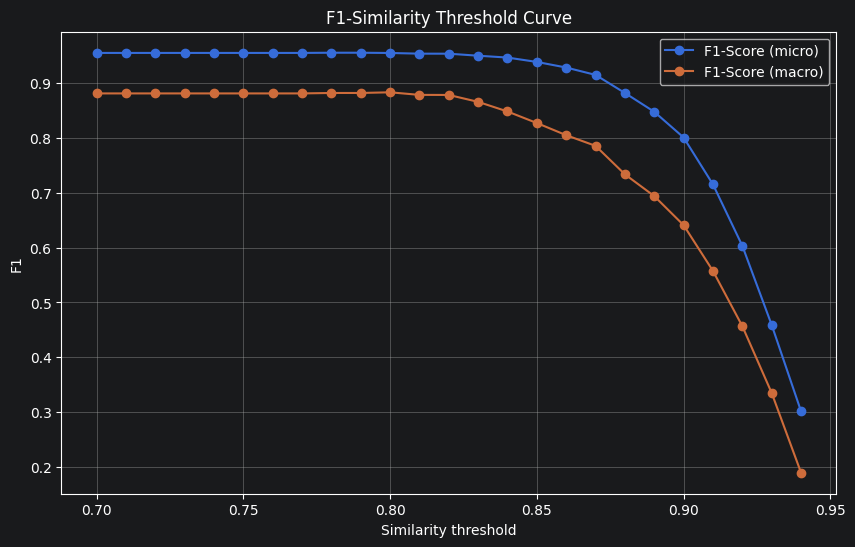

In [39]:
plt.figure(figsize=(10,6))
plt.plot(thresholds, f1score_t_micro, marker='o', label='F1-Score (micro)')
plt.plot(thresholds, f1score_t_macro, marker='o', label='F1-Score (macro)')
plt.xlabel('Similarity threshold')
plt.ylabel('F1')
plt.title('F1-Similarity Threshold Curve')
plt.legend()
plt.grid(True)
plt.show()

On the one hand, the accuracy, precision, recall and f1-score curves no improvement can be seen for larger thresholds. On the other hand, thresholds up to 0.8 do not change the results. Mostly the most confident class is above 0.8 already and results can be subsequently expected to follow that.

### Metrics at different Number of Reference Embeddings & Threshold

To explore where the best values for both lie, it is necessary to not only evaluate them with an indifferent other value but to evaluate them both simultaneously.

In [40]:
thresholds = np.arange(0.7, 0.95, 0.01).tolist()
ref_class_sizes = np.arange(1, 6, 1).tolist()

n_t = len(thresholds)
n_k = len(ref_class_sizes)
accuracies_ct = np.full((n_t, n_k), np.nan)
precisions_ct_micro = np.full((n_t, n_k), np.nan)
recalls_ct_micro = np.full((n_t, n_k), np.nan)
f1score_ct_micro = np.full((n_t, n_k), np.nan)
precisions_ct_macro = np.full((n_t, n_k), np.nan)
recalls_ct_macro = np.full((n_t, n_k), np.nan)
f1score_ct_macro = np.full((n_t, n_k), np.nan)

for j, ref_class_size in enumerate(ref_class_sizes):
    res_ct = await classify_all(df1, limit_per_class=ref_class_size, threshold=0)
    for i, threshold in enumerate(thresholds):
        res_ct['predicted_at_t'] = res_ct.apply(lambda r: r['predicted_class'] if r['confidence'] >= threshold else None, axis=1)
        df_eval_ct = res_ct.copy()
        df_eval_ct['predicted_class'] = df_eval_ct['predicted_at_t']
        metrics_ct = compute_classification_metrics(df_eval_ct, all_classes_1)

        accuracies_ct[i, j] = metrics_ct['accuracy']

        # Micro averaged
        precisions_ct_micro[i, j] = metrics_ct['precision_micro']
        recalls_ct_micro[i, j] = metrics_ct['recall_micro']
        f1score_ct_micro[i, j] = metrics_ct['f1_micro']

        # Macro Averaged
        precisions_ct_macro[i, j] = metrics_ct['precision_macro']
        recalls_ct_macro[i, j] = metrics_ct['recall_macro']
        f1score_ct_macro[i, j] = metrics_ct['f1_macro']


#### Accuracy vs. Number of Reference Embeddings & Threshold

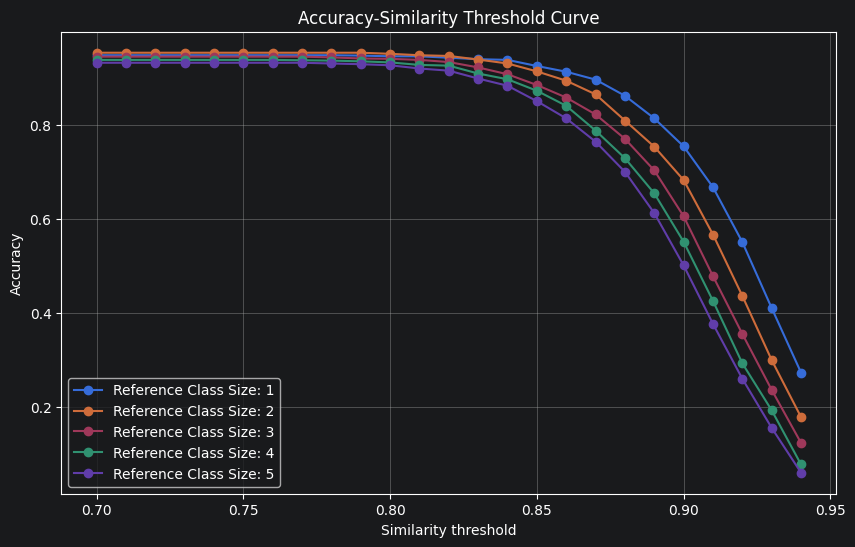

In [41]:
plt.figure(figsize=(10,6))
for i, ref_class_size in enumerate(ref_class_sizes):
    plt.plot(thresholds, accuracies_ct[:, i], marker='o', label=f'Reference Class Size: {ref_class_size}')
plt.xlabel('Similarity threshold')
plt.ylabel('Accuracy')
plt.title('Accuracy-Similarity Threshold Curve')
plt.legend()
plt.grid(True)
plt.show()

#### Precision vs. Number of Reference Embeddings & Threshold

Precision (micro)

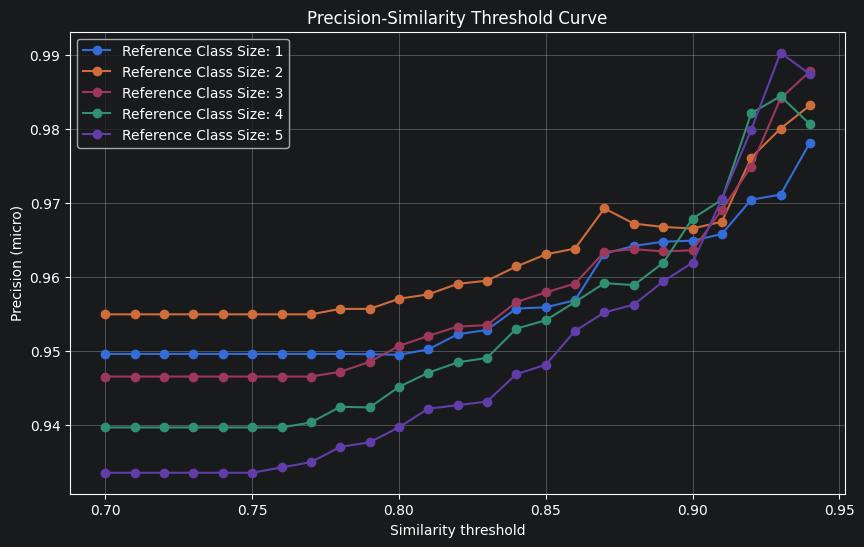

In [42]:
plt.figure(figsize=(10,6))
for i, ref_class_size in enumerate(ref_class_sizes):
    plt.plot(thresholds, precisions_ct_micro[:, i], marker='o', label=f'Reference Class Size: {ref_class_size}')
plt.xlabel('Similarity threshold')
plt.ylabel('Precision (micro)')
plt.title('Precision-Similarity Threshold Curve')
plt.legend()
plt.grid(True)
plt.show()

#### Recall vs. Number of Reference Embeddings & Threshold

Recall (micro)

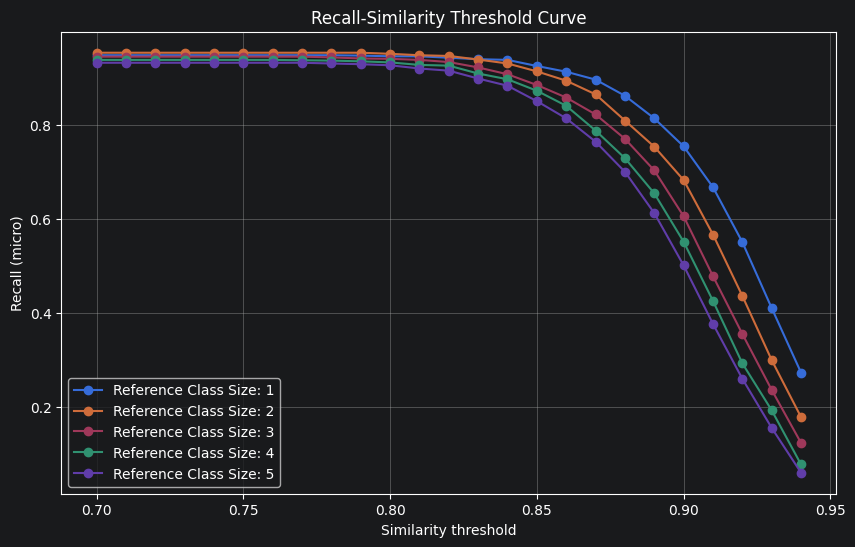

In [43]:
plt.figure(figsize=(10,6))
for i, ref_class_size in enumerate(ref_class_sizes):
    plt.plot(thresholds, recalls_ct_micro[:, i], marker='o', label=f'Reference Class Size: {ref_class_size}')
plt.xlabel('Similarity threshold')
plt.ylabel('Recall (micro)')
plt.title('Recall-Similarity Threshold Curve')
plt.legend()
plt.grid(True)
plt.show()

#### F1-Score vs. Number of Reference Embeddings & Threshold

F1-Score (micro)

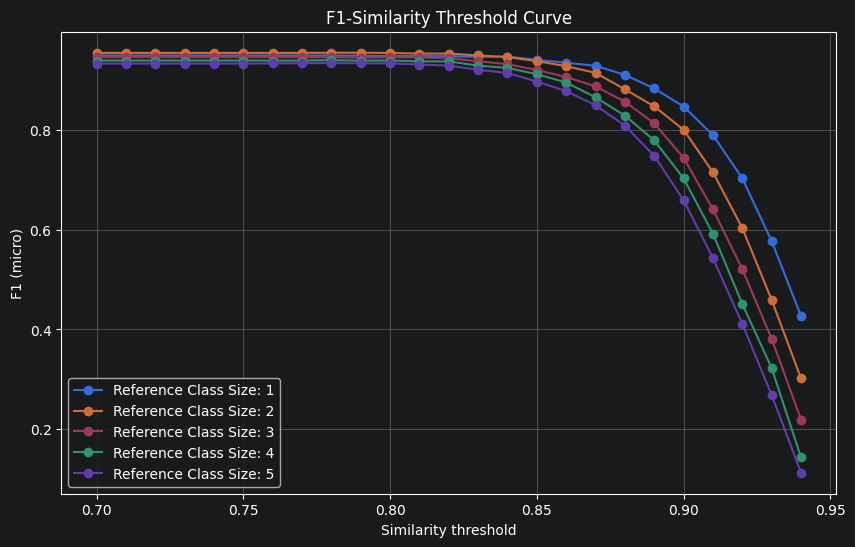

In [44]:
plt.figure(figsize=(10,6))
for i, ref_class_size in enumerate(ref_class_sizes):
    plt.plot(thresholds, f1score_ct_micro[:, i], marker='o', label=f'Reference Class Size: {ref_class_size}')
plt.xlabel('Similarity threshold')
plt.ylabel('F1 (micro)')
plt.title('F1-Similarity Threshold Curve')
plt.legend()
plt.grid(True)
plt.show()